<a href="https://colab.research.google.com/github/vefaceylan/cleaner-power-smarter-timing/blob/main/denmark_energy_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PART 1: The Long-Term Picture**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://nyc3.digitaloceanspaces.com/owid-public/data/energy/owid-energy-data.csv"
df = pd.read_csv(url)

print(df.shape)
df.head()

(23195, 130)


,country,year,iso_code,population,gdp,biofuel_cons_change_pct,biofuel_cons_change_twh,biofuel_cons_per_capita,biofuel_consumption,biofuel_elec_per_capita,...,solar_share_elec,solar_share_energy,wind_cons_change_pct,wind_cons_change_twh,wind_consumption,wind_elec_per_capita,wind_electricity,wind_energy_per_capita,wind_share_elec,wind_share_energy
0,ASEAN (Ember),2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
1,ASEAN (Ember),2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
2,ASEAN (Ember),2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
3,ASEAN (Ember),2003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
4,ASEAN (Ember),2004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN


In [2]:
df.columns.tolist()

['country',
 'year',
 'iso_code',
 'population',
 'gdp',
 'biofuel_cons_change_pct',
 'biofuel_cons_change_twh',
 'biofuel_cons_per_capita',
 'biofuel_consumption',
 'biofuel_elec_per_capita',
 'biofuel_electricity',
 'biofuel_share_elec',
 'biofuel_share_energy',
 'carbon_intensity_elec',
 'coal_cons_change_pct',
 'coal_cons_change_twh',
 'coal_cons_per_capita',
 'coal_consumption',
 'coal_elec_per_capita',
 'coal_electricity',
 'coal_prod_change_pct',
 'coal_prod_change_twh',
 'coal_prod_per_capita',
 'coal_production',
 'coal_share_elec',
 'coal_share_energy',
 'electricity_demand',
 'electricity_demand_per_capita',
 'electricity_generation',
 'electricity_share_energy',
 'energy_cons_change_pct',
 'energy_cons_change_twh',
 'energy_per_capita',
 'energy_per_gdp',
 'fossil_cons_change_pct',
 'fossil_cons_change_twh',
 'fossil_elec_per_capita',
 'fossil_electricity',
 'fossil_energy_per_capita',
 'fossil_fuel_consumption',
 'fossil_share_elec',
 'fossil_share_energy',
 'gas_cons_chan

In [3]:
cols = ["country", "year", "renewables_share_elec", "wind_share_elec", "solar_share_elec", "fossil_share_elec", "carbon_intensity_elec"]
countries = ["Denmark", "United Kingdom"]

data = df[df["country"].isin(countries)][cols]
data.head()

,country,year,renewables_share_elec,wind_share_elec,solar_share_elec,fossil_share_elec,carbon_intensity_elec
5637,Denmark,1900,NaN,NaN,NaN,NaN,NaN
5638,Denmark,1901,NaN,NaN,NaN,NaN,NaN
5639,Denmark,1902,NaN,NaN,NaN,NaN,NaN
5640,Denmark,1903,NaN,NaN,NaN,NaN,NaN
5641,Denmark,1904,NaN,NaN,NaN,NaN,NaN


In [4]:
data = data[data["year"] >= 2000]
data.isna().sum()

,0
country,0
year,0
renewables_share_elec,0
wind_share_elec,0
solar_share_elec,0
fossil_share_elec,0
carbon_intensity_elec,0


In [5]:
data = data.dropna()
print(data.shape)
data.describe()

(50, 7)


,year,renewables_share_elec,wind_share_elec,solar_share_elec,fossil_share_elec,carbon_intensity_elec
count,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000
mean,2012.000000,33.542420,21.284200,1.871940,57.155160,428.447320
std,7.284314,26.134276,18.297149,2.573006,21.711842,153.646146
min,2000.000000,2.479000,0.249000,0.000000,11.961000,143.300000
25%,2006.000000,12.213500,6.070750,0.000000,41.790250,283.535750
50%,2012.000000,27.424000,17.686000,0.349000,63.751000,493.052000
75%,2018.000000,48.240000,31.588000,3.358250,75.022250,549.592500
max,2024.000000,88.039000,57.913000,11.255000,84.463000,651.512000


In [6]:
print(df.shape)

(23195, 130)


In [7]:
test = df[df["country"].isin(countries)][cols]
test.isna().sum()

,0
country,0
year,0
renewables_share_elec,170
wind_share_elec,170
solar_share_elec,170
fossil_share_elec,175
carbon_intensity_elec,200


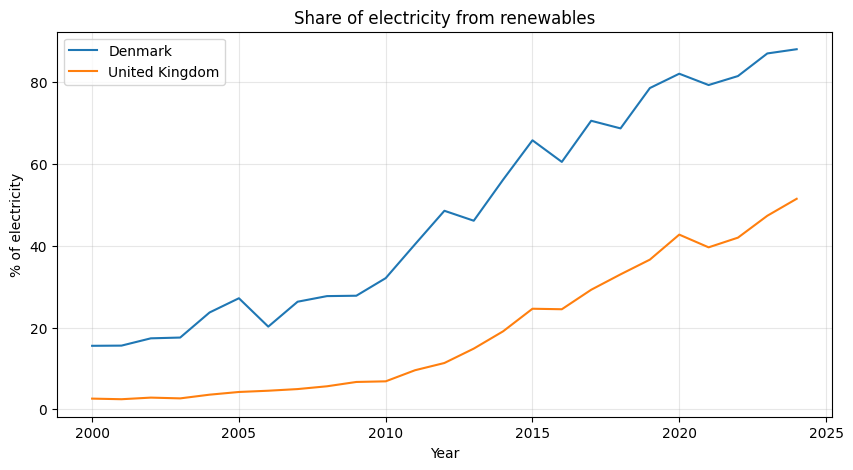

In [8]:
dk = data[data["country"] == "Denmark"]
uk = data[data["country"] == "United Kingdom"]

plt.figure(figsize=(10,5))
plt.plot(dk["year"], dk["renewables_share_elec"], label="Denmark")
plt.plot(uk["year"], uk["renewables_share_elec"], label="United Kingdom")
plt.title("Share of electricity from renewables")
plt.xlabel("Year")
plt.ylabel("% of electricity")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

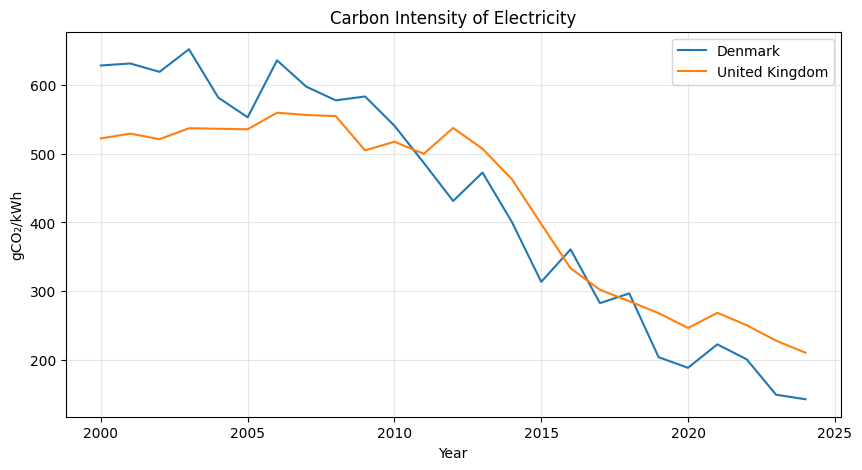

In [9]:
dk = data[data["country"] == "Denmark"]
uk = data[data["country"] == "United Kingdom"]

plt.figure(figsize=(10,5))
plt.plot(dk["year"], dk["carbon_intensity_elec"], label="Denmark")
plt.plot(uk["year"], uk["carbon_intensity_elec"], label="United Kingdom")
plt.title("Carbon Intensity of Electricity")
plt.xlabel("Year")
plt.ylabel("gCO₂/kWh")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [10]:
cols2 = ["country", "renewables_share_elec", "coal_share_elec", "gas_share_elec", "nuclear_share_elec", "carbon_intensity_elec"]
df[(df["country"].isin(countries)) & (df["year"] == 2000)][cols2].T

,5737,21671
country,Denmark,United Kingdom
renewables_share_elec,15.537,2.628
coal_share_elec,46.499,31.812
gas_share_elec,24.463,39.272
nuclear_share_elec,0.0,22.559
carbon_intensity_elec,627.894,521.986


**In 2000, the UK had a lower carbon intensity than Denmark despite having fewer renewables. This is because Denmark relied more heavily on coal (46% vs 32%), the most carbon-intensive source, while the UK generated more of its electricity from gas (24% vs 39%), which emits roughly half as much CO2 as coal, and from nuclear (0% vs 23%), which is low-carbon but not renewable.**

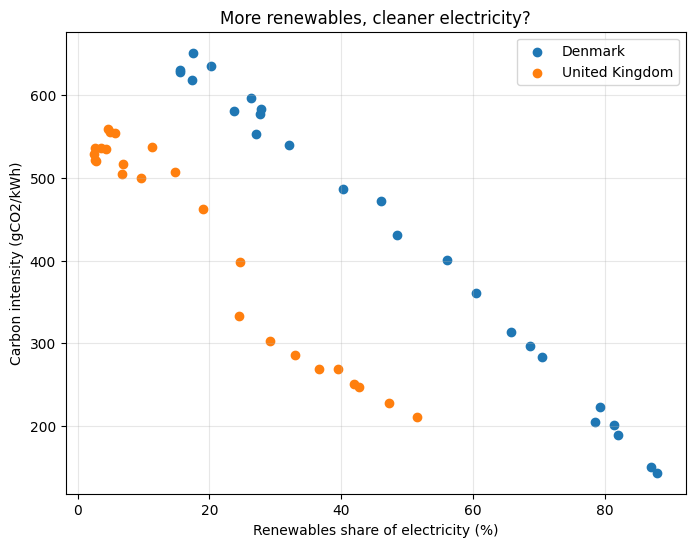

In [11]:
plt.figure(figsize=(8,6))
plt.scatter(dk["renewables_share_elec"], dk["carbon_intensity_elec"], label="Denmark")
plt.scatter(uk["renewables_share_elec"], uk["carbon_intensity_elec"], label="United Kingdom")
plt.xlabel("Renewables share of electricity (%)")
plt.ylabel("Carbon intensity (gCO2/kWh)")
plt.title("More renewables, cleaner electricity?")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [12]:
print("Denmark:", dk["renewables_share_elec"].corr(dk["carbon_intensity_elec"]))
print("UK:", uk["renewables_share_elec"].corr(uk["carbon_intensity_elec"]))

Denmark: -0.9961291787363555
UK: -0.9759264849272048


In [13]:
data.to_csv("denmark_uk_energy_clean.csv", index=False)
from google.colab import files
files.download("denmark_uk_energy_clean.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **PART 2: Hour by hour**

In [14]:
import os
import requests

cache_file = "dk2_co2_2025.csv"

if os.path.exists(cache_file):
  co2 = pd.read_csv(cache_file)
  print("Loaded from file")

else:
  url = "https://api.energidataservice.dk/dataset/CO2Emis"
  params = {
      "start": "2025-01-01",
      "end": "2026-01-01",
      "filter": '{"PriceArea":["DK2"]}',
      "limit": 0
      }
  response = requests.get(url, params=params)
  response.raise_for_status()
  co2 = pd.DataFrame(response.json()["records"])
  co2.to_csv(cache_file, index=False)
  print("Downloaded from API and saved")

print(co2.shape)
co2.head()


Loaded from file
(104535, 4)


,Minutes5UTC,Minutes5DK,PriceArea,CO2Emission
0,2025-12-31T22:55:00,2025-12-31T23:55:00,DK2,29.0
1,2025-12-31T22:50:00,2025-12-31T23:50:00,DK2,29.0
2,2025-12-31T22:45:00,2025-12-31T23:45:00,DK2,30.0
3,2025-12-31T22:40:00,2025-12-31T23:40:00,DK2,30.0
4,2025-12-31T22:35:00,2025-12-31T23:35:00,DK2,30.0


**365 * 24 * 12 = 105,120
However, there are 104,535 lines. So it misses 585 lines and it equals to 49 hours of data.**

In [15]:
co2["time_utc"] = pd.to_datetime(co2["Minutes5UTC"])
co2 = co2.sort_values("time_utc").reset_index(drop=True)

print("Duplicate timestamps:", co2["time_utc"].duplicated().sum())
print("Missing CO2 values:", co2["CO2Emission"].isna().sum())
co2.head()

Duplicate timestamps: 0
Missing CO2 values: 0


,Minutes5UTC,Minutes5DK,PriceArea,CO2Emission,time_utc
0,2024-12-31T23:00:00,2025-01-01T00:00:00,DK2,15.0,2024-12-31 23:00:00
1,2024-12-31T23:05:00,2025-01-01T00:05:00,DK2,16.0,2024-12-31 23:05:00
2,2024-12-31T23:10:00,2025-01-01T00:10:00,DK2,26.0,2024-12-31 23:10:00
3,2024-12-31T23:15:00,2025-01-01T00:15:00,DK2,26.0,2024-12-31 23:15:00
4,2024-12-31T23:20:00,2025-01-01T00:20:00,DK2,28.0,2024-12-31 23:20:00


In [16]:
full_range = pd.date_range(start=co2["time_utc"].min(),
                           end=co2["time_utc"].max(),
                           freq="5min")
missing = full_range.difference(co2["time_utc"])

print("Expected rows:", len(full_range))
print("Missing timestamps:", len(missing))


Expected rows: 105120
Missing timestamps: 585


In [17]:
pd.Series(missing.date).value_counts().sort_index()

,count
2025-01-18,3
2025-01-19,1
2025-05-05,2
2025-05-08,42
2025-08-09,1
2025-09-08,1
2025-09-22,103
2025-09-23,3
2025-10-26,23
2025-11-21,130


In [18]:
hourly = co2.set_index("time_utc")["CO2Emission"].resample("h").mean()

print(hourly.shape)
print("Hours with no data:", hourly.isna().sum)

(8760,)
Hours with no data: <bound method Series.sum of time_utc
2024-12-31 23:00:00    False
2025-01-01 00:00:00    False
2025-01-01 01:00:00    False
2025-01-01 02:00:00    False
2025-01-01 03:00:00    False
                       ...  
2025-12-31 18:00:00    False
2025-12-31 19:00:00    False
2025-12-31 20:00:00    False
2025-12-31 21:00:00    False
2025-12-31 22:00:00    False
Freq: h, Name: CO2Emission, Length: 8760, dtype: bool>


In [19]:
hourly_df = hourly.to_frame(name="co2")
hourly_df.index = hourly.index.tz_localize("UTC").tz_convert("Europe/Copenhagen")
hourly_df.index.name = "time_dk"
hourly_df["hour"] = hourly_df.index.hour
hourly_df["month"] = hourly_df.index.month

hourly_df.head()


,co2,hour,month
time_dk,,,
2025-01-01 00:00:00+01:00,25.083333,0,1
2025-01-01 01:00:00+01:00,63.666667,1,1
2025-01-01 02:00:00+01:00,28.250000,2,1
2025-01-01 03:00:00+01:00,28.166667,3,1
2025-01-01 04:00:00+01:00,23.000000,4,1


<Figure size 640x480 with 0 Axes>

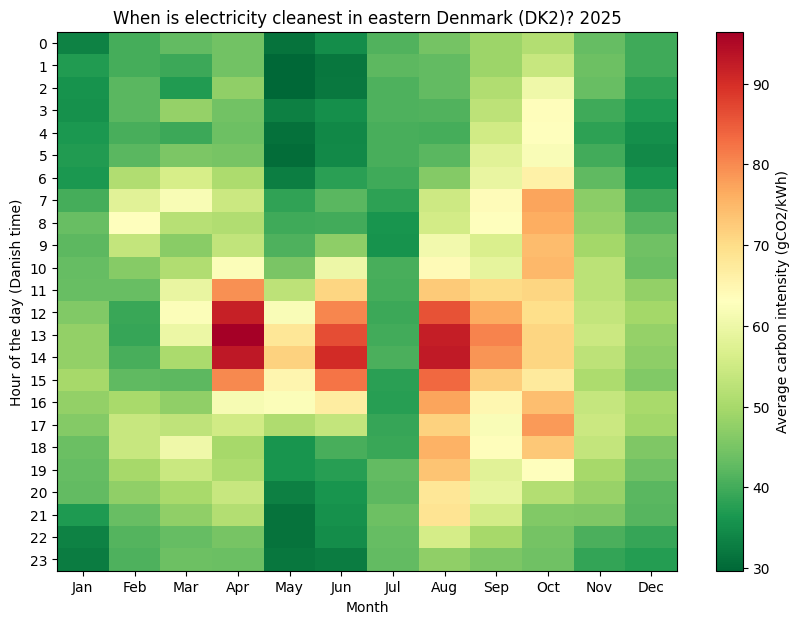

In [20]:
import os
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/heatmap.png", dpi=150, bbox_inches="tight")


pivot = hourly_df.pivot_table(values="co2", index="hour", columns="month", aggfunc="mean")
plt.figure(figsize=(10,7))
plt.imshow(pivot, aspect="auto", cmap="RdYlGn_r")
plt.colorbar(label="Average carbon intensity (gCO2/kWh)")
plt.xticks(range(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                       "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
plt.yticks(range(24))
plt.xlabel("Month")
plt.ylabel("Hour of the day (Danish time)")
plt.title("When is electricity cleanest in eastern Denmark (DK2)? 2025")
plt.show()

# **PART 3: Smart Timing**

In [21]:
df3 = hourly_df.dropna(subset=["co2"]).copy()
df3["date"] = df3.index.date

# Normal Plan: 08:00-12:00
morning = df3[df3["hour"].isin([8,9,10,11])]
baseline = morning.groupby("date")["co2"].agg(["sum", "count"])
baseline = baseline[baseline["count"] == 4]["sum"]

# Smart plan: the cleanest 4 hours of the day
smart = df3.groupby("date")["co2"].apply(lambda s: s.nsmallest(4).sum())

# Comparing both
common = baseline.index.intersection(smart.index)
base_total = baseline[common].sum() / 1000
smart_total = smart[common].sum() / 1000

print("Days compared:", len(common))
print("Normal plan (tonnes CO2):", round(base_total, 1))
print("Smart plan (tonnes CO2):", round(smart_total, 1))
print("Reduction:", round((1 - smart_total / base_total) * 100, 1), "%")

Days compared: 363
Normal plan (tonnes CO2): 77.4
Smart plan (tonnes CO2): 43.6
Reduction: 43.7 %
